# Backtest Autopsy #6: an equal-weight crypto basket with a minimum ticket

**Tags:** cost model

## TL;DR

* **Idea.** Hold five crypto assets at equal weight and rebalance back to equal weight every day, week, two weeks or month; let weights drift in between. Nothing to predict: a "basic" portfolio, to be compared with its own costs.
* **Result at the headline.** On 100,000 USD of illustrative equity, daily rebalancing ends at **63,551 USD** (-36.4%, Sharpe 0.19), against 86,148 USD before costs; monthly rebalancing ends at 85,803 USD (-14.2%) against 88,567 before costs. The basket lost money gross over this window, so most of the headline loss is the market. The **cost** part is real and grows with turnover: daily rebalancing pays 18,220 USD (18.2% of equity), monthly 2,643 USD.
* **Does the ruin survive the sweep?** Partly, and the answer is the point of the case. Equity goes **negative** (the account owes money) only for **daily** rebalancing at **10,000 USD or less**; weekly, two-weekly and monthly rebalancing never reach zero at 5,000 USD or more, and at the headline 100,000 USD nobody does. At an illustrative tiny account of 1,000 USD 3 of the four variants go negative. So "no ruin floor" is a small-account failure, driven by a **minimum ticket of 1.75 USD**: below about 972 USD of traded notional a trade pays the minimum, not a percentage, and the fee is a fixed cost that does not shrink with the account.
* **Verdict number.** At 5,000 USD daily rebalancing, the fixed minimum is 97% of the total cost and the account is wiped out (-13 USD final); the same strategy at 100,000 USD loses -36.4%.
* **Why it matters.** A backtest that lets equity go below zero and keeps trading, with fees that have a floor, is not describing an account that exists. A ruin floor (stop at zero) and the fixed part of the fee belong in the model before any result is read.

> Outputs below come from a run on the real data. With `AUTOPSY_SYNTHETIC=1` the notebook runs end to end on synthetic prices with the same schema and will **not** reproduce the failure.

### Prerequisites

* Python 3.10+, `numpy`, `pandas`, `scipy`, `matplotlib`, `pyarrow`, and the shared package `autopsy_common` (`pip install -e ../..`).
* Familiarity with: rebalancing and weight drift, per-order minimum fees versus proportional fees, drawdown and ruin, and why crypto series are annualised on 365 days.
* Data: your own copy of the minute-level crypto file described in section 2, in a folder named by `AUTOPSY_DATA_DIR`. No data is shipped with this repository.

## 1. Settings (control panel)

One dictionary holds every governing constant.

* **Initial equity.** The headline is **100,000 USD** (an illustrative assumption). The sweep runs from 5,000 to 250,000 USD, with one extra, illustrative **1,000 USD** tiny account in the ruin table (section 7) to show the extreme of the minimum-ticket effect.
* **Costs: public broker fees, plus one assumption.** Commission is **18 basis points of notional with a 1.75 USD minimum per order**, which is the Interactive Brokers published crypto commission schedule for the venue the data comes from (these two numbers were not re-verified against the broker's current page for this publication). Slippage is **5% of the day's high-low range, as a fraction of price, times notional**: an assumption, not a fee.
* **Calendar.** Crypto trades every calendar day, so annualised figures use 365 days.
* **Rebalance frequencies.** Daily, weekly (7-day buckets from the first date), biweekly (14-day buckets) and monthly (calendar months); buy-and-hold drift between rebalances.

In [ ]:
from __future__ import annotations

import json
import os
import time
import warnings
from pathlib import Path
from typing import Any, Dict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from autopsy_common.data import use_synthetic
from autopsy_common.perf import drawdown_series, performance_summary
from autopsy_common.plots import (plot_bar_contribution, plot_capital_sweep, plot_monthly_heatmap, plot_return_distribution,
                                  plot_rolling_risk, plot_yearly_bars)
from autopsy_common.ruin import floor_equity_path, ruin_report
from autopsy_common.schema import check_schema
from autopsy_common.sweep import capital_sweep

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
SYNTHETIC = use_synthetic()
DATA_DIR = Path(os.environ["AUTOPSY_DATA_DIR"]) if os.environ.get("AUTOPSY_DATA_DIR") else None
DATA_FILE = "merged_crypto_1min.parquet"
RESULTS: Dict[str, Any] = {}

ASSETS = ["bch", "btc", "eth", "ltc", "sol"]
FREQUENCIES = ["daily", "weekly", "biweekly", "monthly"]
BUCKET_DAYS = {"daily": 1, "weekly": 7, "biweekly": 14}
PARAMS: Dict[str, Any] = dict(
    capital=100_000.0,                  # illustrative initial equity in USD (an assumption; see the capital sweep)
    commission_bps=18.0,                # published broker crypto commission, basis points of notional
    min_order_usd=1.75,                 # published broker minimum commission per order
    slippage_range_frac=0.05,           # ASSUMPTION: slippage = 5% of the day's high-low range (as a fraction of price) x notional
    periods_per_year=365,
    tiny_capital=1_000.0,               # an extra illustrative tiny account, shown only in the ruin sweep
    random_seed=11,
)
if SYNTHETIC:
    PARAMS["capital"] = 100_000.0
print(f"mode: {'SYNTHETIC' if SYNTHETIC else 'REAL DATA'} | assets: {len(ASSETS)} | frequencies: {FREQUENCIES}")

mode: REAL DATA | assets: 5 | frequencies: ['daily', 'weekly', 'biweekly', 'monthly']


## 2. Data

### 2.1 Source recipe

| Item | Value |
|---|---|
| Vendor / product | Interactive Brokers historical data API, crypto contracts routed to a crypto venue, `TRADES` bars (terms of use: verify before publishing any value) |
| Instruments | five coins: BCH, BTC, ETH, LTC, SOL |
| Frequency | 1 minute (raw), collapsed to one daily close, high and low per coin |
| Time zone | naive timestamps in a fixed UTC-5 offset (no daylight saving) |

**How to rebuild.** One wide table with a `timestamp` column and, per coin, `<coin>_open/high/low/close/volume/bar_count/average/symbol/exchange`. Any provider with one-minute trades for the five coins can be pivoted into that shape. This case reads only the close, high and low columns.

### 2.2 What the strategy consumes

| Column | dtype | Meaning | Units |
|---|---|---|---|
| `date` | datetime | calendar day of the naive minute timestamp | day |
| `asset` | string | coin label | n/a |
| `close` | float64 | last valid close of the day | USD |
| `high` | float64 | day high | USD |
| `low` | float64 | day low | USD |

Key `(date, asset)`, unique, ascending. A coin has no rows before it was listed and no minute data before the file started; the first day of a newly listed coin resolves to its last valid close of that day (not a coincidental late-day gap). A coin joins the equal-weight set the first time it has a price.

In [ ]:
PANEL_SCHEMA = {"date": "datetime", "asset": "string", "close": "float64", "high": "float64", "low": "float64"}
PANEL_KEY = ["date", "asset"]


def daily_panel_from_minute(raw: pd.DataFrame) -> pd.DataFrame:
    raw = raw.copy()
    raw["timestamp"] = pd.to_datetime(raw["timestamp"])
    raw = raw.set_index("timestamp").sort_index()
    day = raw.index.floor("D")
    frames = []
    for a in ASSETS:
        c = raw[f"{a}_close"]
        close = c.groupby(day).apply(lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan)
        high = raw[f"{a}_high"].groupby(day).max()
        low = raw[f"{a}_low"].groupby(day).min()
        f = pd.DataFrame({"close": close, "high": high, "low": low}).dropna(subset=["close"])
        f.index.name = "date"
        f = f.reset_index()
        f.insert(1, "asset", a)
        frames.append(f)
    return pd.concat(frames, ignore_index=True).sort_values(PANEL_KEY).reset_index(drop=True)


def synthetic_panel(n_days: int = 1600, seed: int = 4, start: str = "2021-08-15") -> pd.DataFrame:
    """Synthetic daily closes/highs/lows for five assets, some listed late. Driftless random walks."""
    rng = np.random.default_rng(seed)
    dates = pd.date_range(start, periods=n_days, freq="D")
    frames = []
    for i, a in enumerate(ASSETS):
        ret = rng.normal(0.0, 0.035, n_days)
        close = 100.0 * np.exp(np.cumsum(ret))
        high = close * (1 + np.abs(rng.normal(0, 0.02, n_days)))
        low = close * (1 - np.abs(rng.normal(0, 0.02, n_days)))
        start_i = 0 if i < 4 else n_days // 3
        frames.append(pd.DataFrame({"date": dates[start_i:], "asset": a, "close": np.round(close[start_i:], 4),
                                    "high": np.round(high[start_i:], 4), "low": np.round(low[start_i:], 4)}))
    return pd.concat(frames, ignore_index=True).sort_values(PANEL_KEY).reset_index(drop=True)


def load_panel() -> pd.DataFrame:
    if SYNTHETIC:
        df = synthetic_panel()
    else:
        if DATA_DIR is None:
            raise RuntimeError("Set AUTOPSY_SYNTHETIC=1, or AUTOPSY_DATA_DIR to the folder with the minute crypto file.")
        cache = DATA_DIR / "crypto_daily_panel.parquet"
        if cache.exists():
            df = pd.read_parquet(cache)
        else:
            cols = ["timestamp"] + [f"{a}_{f}" for a in ASSETS for f in ("close", "high", "low")]
            df = daily_panel_from_minute(pd.read_parquet(DATA_DIR / DATA_FILE, columns=cols))
            df.to_parquet(cache, index=False)
        df = df.sort_values(PANEL_KEY).reset_index(drop=True)
    df = df[list(PANEL_SCHEMA)]
    check_schema(df, PANEL_SCHEMA, PANEL_KEY)
    return df


PANEL = load_panel()
print("schema check passed:", True)
print("key unique:", not bool(PANEL.duplicated(PANEL_KEY).any()), "| sorted:", bool(PANEL.sort_values(PANEL_KEY).index.equals(PANEL.index)))
print("no nulls:", not bool(PANEL.isna().any().any()), "| high >= close >= low everywhere:",
      bool(((PANEL["high"] >= PANEL["close"]) & (PANEL["close"] >= PANEL["low"])).all()), "| all five assets present:",
      sorted(PANEL["asset"].unique()) == sorted(ASSETS))

PRICES = PANEL.pivot(index="date", columns="asset", values="close")[ASSETS]
DAY_HIGH = PANEL.pivot(index="date", columns="asset", values="high")[ASSETS]
DAY_LOW = PANEL.pivot(index="date", columns="asset", values="low")[ASSETS]

schema check passed: True
key unique: True | sorted: True
no nulls: True | high >= close >= low everywhere: True | all five assets present: True


## 3. Step 1: the fee model, and the minimum ticket

The cost of one order of notional `V` (USD) at a price `P` on a day with high `H` and low `L`:

```
commission = max(V x 18 / 10,000, 1.75)
slippage   = V x ((H - L) / P) x 0.05
cost       = commission + slippage
```

The commission has a **floor**: for any order below `1.75 / 0.0018` USD of notional, the commission is the flat 1.75 USD, not 18 basis points. That threshold is the **break-even ticket**. Below it, the *effective* fee in basis points is `1.75 / V`: 35 basis points on a 500 USD order, 175 basis points on a 100 USD order. A rebalance of a five-asset equal-weight book touches several assets, and the order for each is only the *drift correction*, a fraction of the position. At small equity the drift corrections are tiny and nearly all of them pay the minimum.

What can go wrong: the slippage term is proportional to the day's range, so it is *large* on the volatile days when the portfolio most needs to rebalance, and it is an assumption, not a measured fill.

In [ ]:
def trade_cost(notional: float, day_high: float, day_low: float, price: float, p: Dict[str, Any]):
    """Return (total cost, fixed part, proportional part). `fixed` is the extra paid because the minimum binds."""
    prop_comm = notional * p["commission_bps"] / 1e4
    comm = max(prop_comm, p["min_order_usd"])
    day_range_frac = (day_high - day_low) / price if price > 0 else 0.0
    slip = notional * day_range_frac * p["slippage_range_frac"]
    return comm + slip, comm - prop_comm if comm > prop_comm else 0.0, (prop_comm if comm == prop_comm else 0.0) + slip


min_notional = PARAMS["min_order_usd"] / (PARAMS["commission_bps"] / 1e4)
print(f"break-even ticket: orders below {min_notional:,.0f} USD pay the {PARAMS['min_order_usd']:.2f} USD minimum")
for v in (50, 200, 500, 1000, 5000):
    print(f"  order of {v:>5,} USD: commission {max(v * PARAMS['commission_bps'] / 1e4, PARAMS['min_order_usd']):.2f} USD = "
          f"{max(v * PARAMS['commission_bps'] / 1e4, PARAMS['min_order_usd']) / v * 1e4:.0f} bp")
RESULTS.update({"min_notional_usd": float(min_notional), "min_ticket": float(PARAMS["min_order_usd"])})

break-even ticket: orders below 972 USD pay the 1.75 USD minimum
  order of    50 USD: commission 1.75 USD = 350 bp
  order of   200 USD: commission 1.75 USD = 88 bp
  order of   500 USD: commission 1.75 USD = 35 bp
  order of 1,000 USD: commission 1.80 USD = 18 bp
  order of 5,000 USD: commission 9.00 USD = 18 bp


## 4. Step 2: the simulation

At each date: the day's return of each held asset grows its weight; on a rebalance date the book trades back to equal weight over the assets that are listed at that date, paying the cost of every order (the delta of each weight times equity). Between rebalances weights drift. Equity compounds on the day's return and is reduced by the cost on the rebalance day.

**No ruin floor.** Nothing stops the simulation when equity reaches zero. Equity can go negative, the fee floor keeps applying, and weights computed from a negative equity are meaningless; the simulation does not guard against it, and the guard is part of what this case is about. Two things are therefore tracked explicitly: the **first day on which equity is at or below zero** (a day number, counted from the first row) and the equity path **stopped at ruin** (frozen at zero from that day on, `floor_equity_path`).

The fixed part of the cost (what the minimum adds on top of the proportional commission) is recorded separately so the capital sweep can show how much of the cost is a floor.

In [ ]:
def rebalance_dates(index: pd.DatetimeIndex, frequency: str) -> pd.DatetimeIndex:
    if frequency == "monthly":
        groups = index.to_period("M")
    else:
        groups = (index - index[0]).days // BUCKET_DAYS[frequency]
    first = pd.Series(index, index=index).groupby(groups).first()
    return pd.DatetimeIndex(first.values)


def simulate(prices: pd.DataFrame, hi: pd.DataFrame, lo: pd.DataFrame, frequency: str, capital: float,
             p: Dict[str, Any], apply_costs: bool = True) -> pd.DataFrame:
    returns = prices.pct_change()
    rdates = set(rebalance_dates(prices.index, frequency))

    def equal_weights(active: pd.Series) -> pd.Series:
        n = int(active.sum())
        return pd.Series(np.where(active, 1.0 / n if n else 0.0, 0.0), index=prices.columns)

    def costs_of(delta: pd.Series, date, equity: float):
        if not apply_costs:
            return 0.0, 0.0, 0
        total = fixed = 0.0
        orders = 0
        for asset, dw in delta.items():
            notional = abs(dw) * equity
            if notional <= 0:
                continue
            price = prices.at[date, asset]
            if not np.isfinite(price) or price <= 0:
                continue
            c, f, _ = trade_cost(notional, hi.at[date, asset], lo.at[date, asset], price, p)
            total += c
            fixed += f
            orders += 1
        return total, fixed, orders

    d0 = prices.index[0]
    w = equal_weights(prices.iloc[0].notna())
    equity = capital
    c0, f0, o0 = costs_of(w, d0, equity)
    equity -= c0
    rec = [{"date": d0, "equity": equity, "cost": c0, "fixed_cost": f0, "orders": o0, "turnover": float(w.abs().sum())}]
    for date in prices.index[1:]:
        day_ret = returns.loc[date].fillna(0.0)
        grown = w * (1.0 + day_ret)
        tot = grown.sum()
        equity *= 1.0 + float((w * day_ret).sum())
        w = grown / tot if tot > 0 else w
        cost = fixed = 0.0
        orders, turn = 0, 0.0
        if date in rdates:
            new_w = equal_weights(prices.loc[date].notna())
            delta = new_w - w
            cost, fixed, orders = costs_of(delta, date, equity)
            turn = float(delta.abs().sum())
            w = new_w
            equity -= cost
        rec.append({"date": date, "equity": equity, "cost": cost, "fixed_cost": fixed, "orders": orders, "turnover": turn})
    out = pd.DataFrame(rec).set_index("date")
    out["daily_return"] = out["equity"].pct_change()
    out.iloc[0, out.columns.get_loc("daily_return")] = out["equity"].iloc[0] / capital - 1.0
    return out


t0 = time.time()
CURVES = {f: simulate(PRICES, DAY_HIGH, DAY_LOW, f, PARAMS["capital"], PARAMS) for f in FREQUENCIES}
GROSS = {f: simulate(PRICES, DAY_HIGH, DAY_LOW, f, PARAMS["capital"], PARAMS, apply_costs=False) for f in FREQUENCIES}
print(f"four headline simulations (net and gross) in {time.time() - t0:.1f}s")

four headline simulations (net and gross) in 3.9s


## 5. Results and metrics at the headline equity

Returns are daily and annualised on 365 days. The strategy defines **no benchmark**, so none is added: the baseline for each frequency is the same simulation **without costs** (gross), and cash. **Exposure** is always 1 (fully invested); **turnover** is the sum of absolute weight changes at rebalances.

In [ ]:
ppy = int(PARAMS["periods_per_year"])
cap = float(PARAMS["capital"])
rows = {}
for f in FREQUENCIES:
    c, g = CURVES[f], GROSS[f]
    sm = performance_summary(c["daily_return"].iloc[1:], periods_per_year=ppy, gross_returns=g["daily_return"].iloc[1:],
                             turnover=c["turnover"].iloc[1:], exposure=pd.Series(1.0, index=c.index[1:]))
    rows[f] = {"final_equity": float(c["equity"].iloc[-1]), "gross_final_equity": float(g["equity"].iloc[-1]),
               "total_return": float(c["equity"].iloc[-1] / cap - 1.0), "cagr": float(sm["cagr"]), "sharpe": float(sm["sharpe"]),
               "max_drawdown": float(sm["max_drawdown"]), "cost_usd": float(c["cost"].sum()), "cost_share": float(c["cost"].sum() / cap),
               "fixed_cost_usd": float(c["fixed_cost"].sum()), "orders": int(c["orders"].sum()), "turnover_sum": float(c["turnover"].sum())}
head = pd.DataFrame(rows).T
display(head.round(4))
for f in ("daily", "monthly"):
    RESULTS.update({f"h_{f}_final": rows[f]["final_equity"], f"h_{f}_ret": rows[f]["total_return"], f"h_{f}_sharpe": rows[f]["sharpe"],
                    f"h_{f}_gross_final": rows[f]["gross_final_equity"], f"h_{f}_cost": rows[f]["cost_usd"],
                    f"h_{f}_cost_share": rows[f]["cost_share"], f"h_{f}_mdd": rows[f]["max_drawdown"], f"h_{f}_cagr": rows[f]["cagr"]})
RESULTS["headline_table"] = head.round(6).reset_index().to_dict("records")
ext = pd.DataFrame({f: performance_summary(CURVES[f]["daily_return"].iloc[1:], periods_per_year=ppy) for f in FREQUENCIES})
display(ext.loc[["cagr", "ann_vol", "sharpe", "sortino", "calmar", "max_drawdown", "max_drawdown_duration", "hit_rate",
                 "profit_factor", "skew", "kurtosis", "var_95", "cvar_95", "best_month", "worst_month"]].round(4))

,final_equity,gross_final_equity,total_return,cagr,sharpe,max_drawdown,cost_usd,cost_share,fixed_cost_usd,orders,turnover_sum
daily,63550.8174,86147.5388,-0.3645,-0.0970,0.1910,-0.8004,18220.3223,0.1822,9739.1341,6916.0,21.7824
weekly,82444.0412,88434.4307,-0.1756,-0.0419,0.2788,-0.7925,5163.8804,0.0516,1080.6427,1154.0,10.1579
biweekly,84229.7772,88001.3596,-0.1577,-0.0372,0.2866,-0.7943,3323.2874,0.0332,426.5129,582.0,7.4959
monthly,85802.9651,88566.5100,-0.1420,-0.0331,0.2936,-0.7946,2643.2266,0.0264,135.2942,271.0,5.7526


,daily,weekly,biweekly,monthly
cagr,-0.0970,-0.0419,-0.0372,-0.0331
ann_vol,0.6768,0.6776,0.6791,0.6806
sharpe,0.1910,0.2788,0.2866,0.2936
sortino,0.2648,0.3875,0.3993,0.4091
calmar,-0.1211,-0.0529,-0.0468,-0.0417
max_drawdown,-0.8004,-0.7925,-0.7943,-0.7946
max_drawdown_duration,1531.0000,961.0000,960.0000,959.0000
hit_rate,0.4991,0.5009,0.5009,0.5028
profit_factor,1.0284,1.0417,1.0430,1.0441
skew,-0.2581,-0.2436,-0.2178,-0.2032


## 6. Plots

### 6.1 Equity, drawdown, rolling risk, calendar and distribution (headline equity)

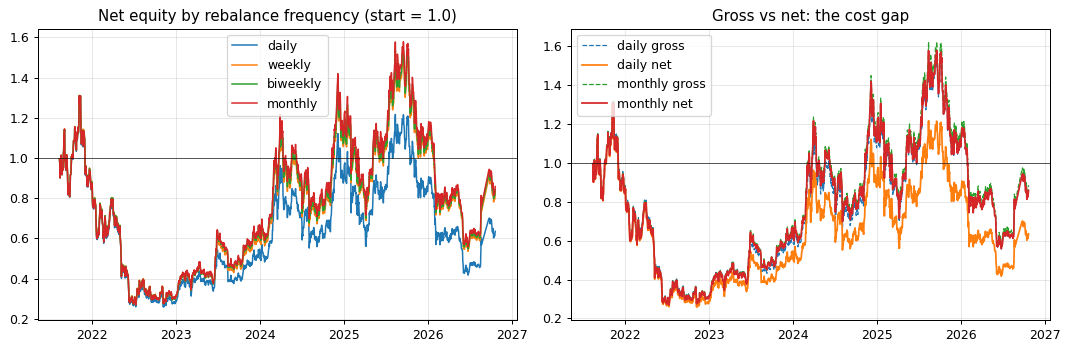

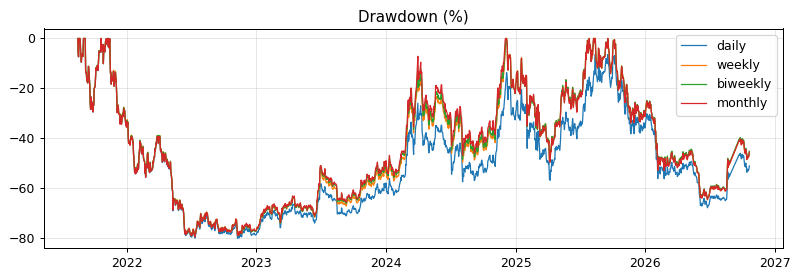

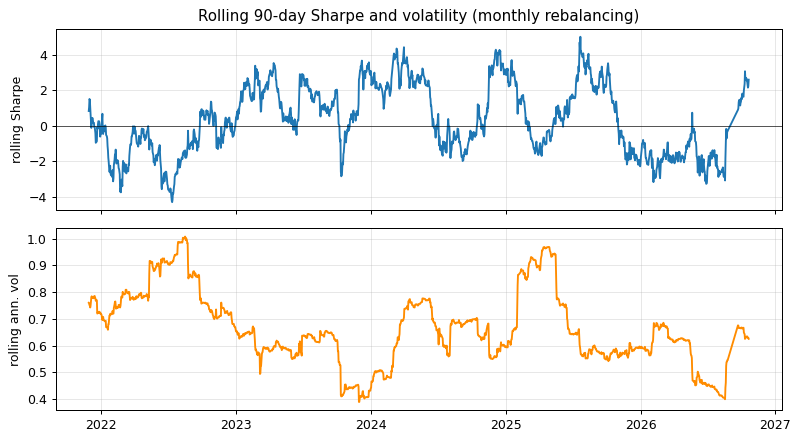

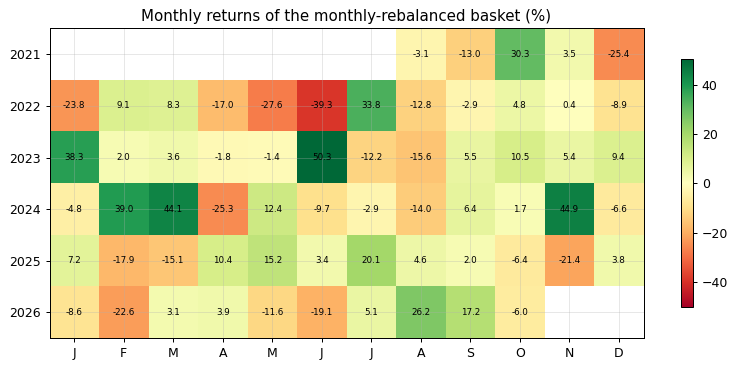

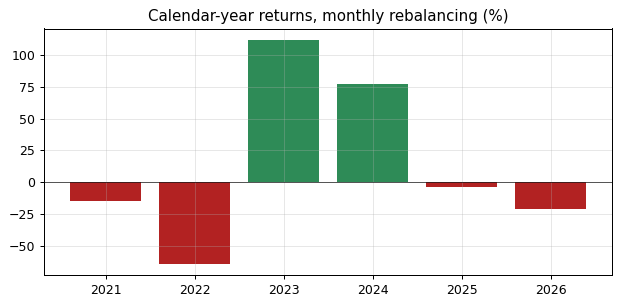

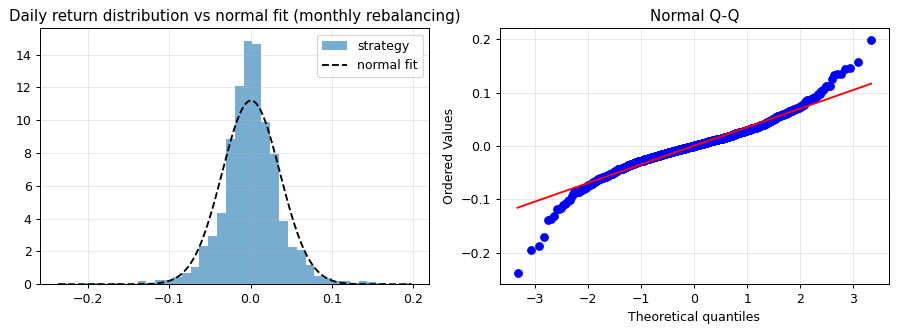

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for f in FREQUENCIES:
    axes[0].plot(CURVES[f]["equity"] / cap, label=f, lw=1.2)
axes[0].axhline(1.0, color="k", lw=0.5)
axes[0].set_title("Net equity by rebalance frequency (start = 1.0)")
axes[0].legend()
for f in ("daily", "monthly"):
    axes[1].plot(GROSS[f]["equity"] / cap, label=f"{f} gross", ls="--", lw=1.0)
    axes[1].plot(CURVES[f]["equity"] / cap, label=f"{f} net", lw=1.4)
axes[1].axhline(1.0, color="k", lw=0.5)
axes[1].set_title("Gross vs net: the cost gap")
axes[1].legend()
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(9, 3.2))
for f in FREQUENCIES:
    ax.plot(drawdown_series(CURVES[f]["daily_return"].iloc[1:]) * 100, label=f, lw=1.0)
ax.set_title("Drawdown (%)")
ax.legend()
fig.tight_layout()
plt.show()
mrets = CURVES["monthly"]["daily_return"].iloc[1:]
plot_rolling_risk(mrets, window=90, periods_per_year=ppy, title="Rolling 90-day Sharpe and volatility (monthly rebalancing)")
plt.show()
plot_monthly_heatmap(mrets, title="Monthly returns of the monthly-rebalanced basket (%)")
plt.show()
plot_yearly_bars(mrets, title="Calendar-year returns, monthly rebalancing (%)")
plt.show()
plot_return_distribution(mrets, title="Daily return distribution vs normal fit (monthly rebalancing)")
plt.show()

### 6.2 Where the cost goes

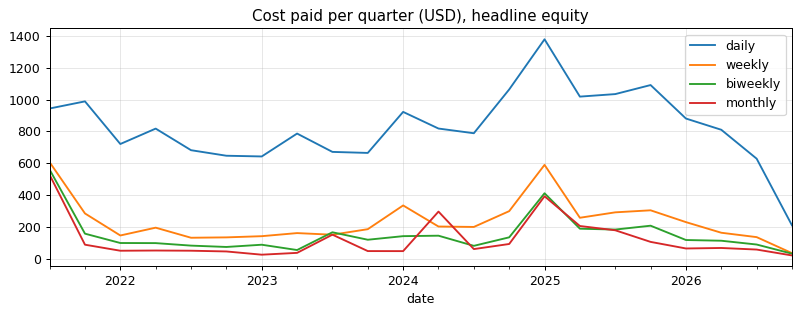

orders per year: {'daily': 1572, 'weekly': 262, 'biweekly': 132, 'monthly': 62}


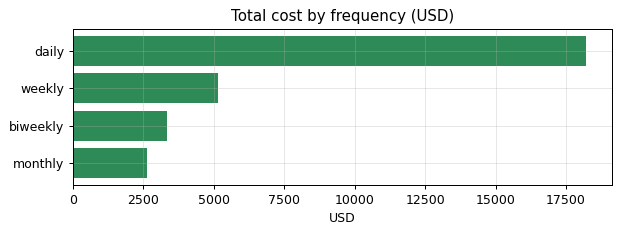

In [ ]:
cd = pd.DataFrame({f: CURVES[f]["cost"].resample("QE").sum() for f in FREQUENCIES})
fig, ax = plt.subplots(figsize=(9, 3.6))
cd.plot(ax=ax)
ax.set_title("Cost paid per quarter (USD), headline equity")
fig.tight_layout()
plt.show()
orders_per_year = {f: CURVES[f]["orders"].sum() / (len(CURVES[f]) / 365.0) for f in FREQUENCIES}
print("orders per year:", {k: round(v) for k, v in orders_per_year.items()})
fig = plot_bar_contribution(pd.Series({f: CURVES[f]["cost"].sum() for f in FREQUENCIES}), title="Total cost by frequency (USD)", xlabel="USD")
plt.show()

## 7. The killing test: does the loss survive the capital sweep?

The question this case asks, answered by running it: **at which equity levels, and for which rebalance frequency, does the account reach zero?** Six equity levels from 5,000 to 250,000 USD plus an illustrative 1,000 USD tiny account (first row), four frequencies each. Only the initial equity changes; nothing is retuned. For every run: final equity, the lowest equity reached, whether equity is at or below zero on any day, and the first such day (counted from the first row).

Reading it needs one more number per run, the **share of the cost that is the fixed minimum** (what the 1.75 USD floor adds beyond 18 basis points), which is the mechanism.

In [ ]:
def one_run(cap_: float, f: str) -> Dict[str, float]:
    c = simulate(PRICES, DAY_HIGH, DAY_LOW, f, float(cap_), PARAMS)
    eq = c["equity"]
    rr = ruin_report(eq, floor=0.0)
    tot_cost = float(c["cost"].sum())
    return {"final_equity": float(eq.iloc[-1]), "min_equity": float(eq.min()), "ruined": float(rr["breached"]),
            "first_breach_day": float(rr["first_breach_position"]) if rr["breached"] else np.nan,
            "share_days_at_or_below_zero": float(rr["share_at_or_below_floor"]),
            "cost_usd": tot_cost, "cost_share": tot_cost / cap_,
            "fixed_share_of_cost": float(c["fixed_cost"].sum() / tot_cost) if tot_cost > 0 else np.nan,
            "final_return": float(eq.iloc[-1] / cap_ - 1.0)}


CAPS = [PARAMS["tiny_capital"], 5_000, 10_000, 25_000, 50_000, 100_000, 250_000]
if SYNTHETIC:
    CAPS = [PARAMS["tiny_capital"], 5_000, 100_000]
t0 = time.time()
grid = {(cp, f): one_run(cp, f) for cp in CAPS for f in FREQUENCIES}
print(f"{len(grid)} simulations in {time.time() - t0:.0f}s")
tbl = pd.DataFrame(grid).T
tbl.index.names = ["capital", "frequency"]
for metric, label in (("final_equity", "final equity (USD)"), ("min_equity", "lowest equity reached (USD)"),
                      ("ruined", "equity at or below zero on some day (1 = yes)"), ("first_breach_day", "first day at or below zero (day number)")):
    print(label)
    display(tbl[metric].unstack("frequency")[FREQUENCIES].round(1))
print("share of cost that is the fixed minimum:")
display((tbl["fixed_share_of_cost"].unstack("frequency")[FREQUENCIES] * 100).round(1))
ruined = tbl["ruined"].unstack("frequency")[FREQUENCIES]
ge5 = ruined[ruined.index >= 5_000]
RESULTS.update({
    "orig_cap": float(PARAMS["tiny_capital"]), "tiny_ruin_count": int(ruined.loc[PARAMS["tiny_capital"]].sum()), "n_grid_ge5k": int(ge5.size),
    "ruin_all_at_orig": bool((ruined.loc[PARAMS["tiny_capital"]] == 1).all()),
    "ruin_count_ge5k": int(ge5.to_numpy().sum()),
    "ruin_daily_max_cap": float(max([c for c in ruined.index if ruined.loc[c, "daily"] == 1 and c >= 5_000] or [0])),
    "ruin_nondaily_ge5k": int(ge5[["weekly", "biweekly", "monthly"]].to_numpy().sum()),
    "ruin_at_100k": int(ruined.loc[100_000].sum()),
    "daily_5k_final": float(tbl.loc[(5_000, "daily"), "final_equity"]),
    "fixed_share_5k": float(tbl.loc[(5_000, "daily"), "fixed_share_of_cost"]),
    "fixed_share_100k": float(tbl.loc[(100_000, "daily"), "fixed_share_of_cost"]),
    "weekly_5k_final": float(tbl.loc[(5_000, "weekly"), "final_equity"]),
    "monthly_5k_ret": float(tbl.loc[(5_000, "monthly"), "final_return"]),
    "daily_orig_final": float(tbl.loc[(PARAMS["tiny_capital"], "daily"), "final_equity"]),
    "daily_5k_breach_day": float(tbl.loc[(5_000, "daily"), "first_breach_day"]) if tbl.loc[(5_000, "daily"), "ruined"] == 1 else None,
    "n_days": int(len(PRICES)),
    "grid": tbl.round(6).reset_index().to_dict("records")})

28 simulations in 15s
final equity (USD)


frequency,daily,weekly,biweekly,monthly
capital,,,,
1000.0,-1.4,-1.5,-4.4,254.1
5000.0,-13.1,1631.7,2967.4,3728.5
10000.0,-9.7,5900.4,7258.7,8063.7
25000.0,4454.7,18698.9,20122.9,21056.9
50000.0,24181.4,39993.2,41530.3,42674.9
100000.0,63550.8,82444.0,84229.8,85803.0
250000.0,180765.8,209093.9,211835.1,214929.1


lowest equity reached (USD)


frequency,daily,weekly,biweekly,monthly
capital,,,,
1000.0,-2.5,-2.7,-8.0,191.9
5000.0,-23.7,1154.8,1263.3,1315.2
10000.0,-17.6,2560.7,2638.0,2662.0
25000.0,3424.5,6699.1,6694.8,6702.4
50000.0,12240.0,13534.2,13454.9,13435.9
100000.0,25911.3,27197.4,26967.5,26894.8
250000.0,66156.3,68141.1,67477.5,67255.8


equity at or below zero on some day (1 = yes)


frequency,daily,weekly,biweekly,monthly
capital,,,,
1000.0,1.0,1.0,1.0,0.0
5000.0,1.0,0.0,0.0,0.0
10000.0,1.0,0.0,0.0,0.0
25000.0,0.0,0.0,0.0,0.0
50000.0,0.0,0.0,0.0,0.0
100000.0,0.0,0.0,0.0,0.0
250000.0,0.0,0.0,0.0,0.0


first day at or below zero (day number)


frequency,daily,weekly,biweekly,monthly
capital,,,,
1000.0,137.0,420.0,876.0,NaN
5000.0,376.0,NaN,NaN,NaN
10000.0,661.0,NaN,NaN,NaN
25000.0,NaN,NaN,NaN,NaN
50000.0,NaN,NaN,NaN,NaN
100000.0,NaN,NaN,NaN,NaN
250000.0,NaN,NaN,NaN,NaN


share of cost that is the fixed minimum:


frequency,daily,weekly,biweekly,monthly
capital,,,,
1000.0,99.0,98.0,98.1,96.6
5000.0,96.7,93.4,88.7,78.8
10000.0,95.5,84.6,77.5,62.5
25000.0,89.6,63.9,53.2,34.2
50000.0,74.7,42.0,30.7,15.4
100000.0,53.5,20.9,12.8,5.1
250000.0,23.5,5.5,2.6,0.9


### 7.1 What a ruin floor would do

Stopping at ruin turns "equity of -13 USD" into "an empty account". The table shows, for the runs that do hit zero, the equity path stopped at the first breach (frozen at zero) and the share of the sample the account would have been alive. A real broker would not let the account trade on after the margin call; a model without a floor reports a loss of 100% as something that can exceed 100%.

final_equity_no_floor  final_equity_floored  \
capital frequency                                                
1000.0  daily                     -1.392                   0.0   
        weekly                    -1.484                   0.0   
        biweekly                  -4.397                   0.0   
5000.0  daily                    -13.140                   0.0   
10000.0 daily                     -9.742                   0.0   

                   share_of_sample_alive  return_no_floor  
capital frequency                                          
1000.0  daily                      0.085           -1.001  
        weekly                     0.262           -1.001  
        biweekly                   0.545           -1.004  
5000.0  daily                      0.234           -1.003  
10000.0 daily                      0.412           -1.001

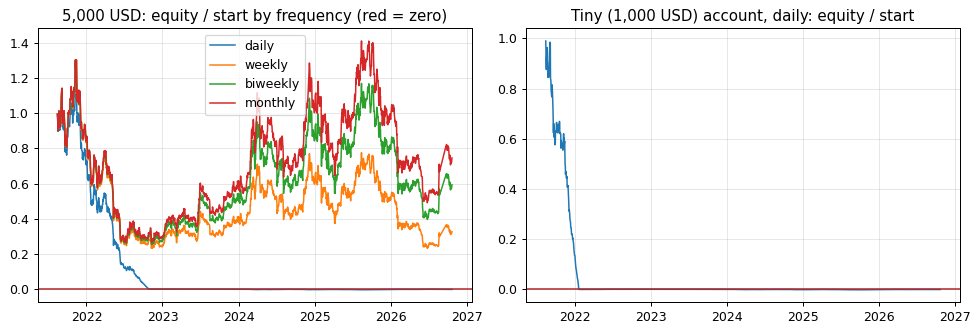

In [ ]:
rows = []
for (cp, f), r in grid.items():
    if r["ruined"] == 1:
        c = simulate(PRICES, DAY_HIGH, DAY_LOW, f, float(cp), PARAMS)
        stopped = floor_equity_path(c["equity"], floor=0.0)
        alive = float((stopped > 0).mean())
        rows.append({"capital": cp, "frequency": f, "final_equity_no_floor": float(c["equity"].iloc[-1]),
                     "final_equity_floored": float(stopped.iloc[-1]), "share_of_sample_alive": alive,
                     "return_no_floor": float(c["equity"].iloc[-1] / cp - 1.0)})
fl = pd.DataFrame(rows).set_index(["capital", "frequency"])
display(fl.round(3))
RESULTS["n_ruined_runs"] = int(len(fl))
RESULTS["worst_return_no_floor"] = float(fl["return_no_floor"].min()) if len(fl) else None
if len(fl):
    e5 = fl.reset_index()
    sub = e5[(e5["capital"] == 5_000) & (e5["frequency"] == "daily")]
    RESULTS["daily_5k_alive"] = float(sub["share_of_sample_alive"].iloc[0]) if len(sub) else None
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for f in FREQUENCIES:
    c = simulate(PRICES, DAY_HIGH, DAY_LOW, f, 5_000.0, PARAMS)
    axes[0].plot(c["equity"] / 5_000.0, label=f, lw=1.2)
axes[0].axhline(0.0, color="firebrick", lw=1.2)
axes[0].set_title("5,000 USD: equity / start by frequency (red = zero)")
axes[0].legend()
c = simulate(PRICES, DAY_HIGH, DAY_LOW, "daily", float(PARAMS["tiny_capital"]), PARAMS)
axes[1].plot(c["equity"] / PARAMS["tiny_capital"], lw=1.2)
axes[1].axhline(0.0, color="firebrick", lw=1.2)
axes[1].set_title("Tiny (1,000 USD) account, daily: equity / start")
fig.tight_layout()
plt.show()

## 8. Why the minimum ticket makes the loss non-linear in capital

The next table is the capital sweep for **daily** and **monthly** rebalancing, headline columns first. The cost split is the point: as equity falls, the fixed part of the fee grows from a rounding error to most of the bill, and the **cost as a share of equity** rises faster than 1 over equity.

capital sweep, daily rebalancing


capital,5000,10000,25000,50000,100000,250000
gross_usd,-692.623,-1385.246,-3463.115,-6926.231,-13852.461,-34631.153
net_usd,-5013.140,-10009.742,-20545.250,-25818.591,-36449.183,-69234.239
net_return,-100.260,-100.100,-82.180,-51.640,-36.450,-27.690
cost_share,54.010,47.920,52.270,29.500,18.220,11.850
sharpe,-1.360,-1.593,-0.236,0.099,0.191,0.234
max_drawdown,-100.000,-100.000,-89.280,-81.050,-80.040,-79.680
fixed_cost_usd,2611.938,4574.394,11711.554,11018.776,9739.134,6960.479
proportional_cost_usd,88.522,217.131,1356.185,3732.947,8481.188,22675.399
cost_usd,2700.461,4791.525,13067.739,14751.723,18220.322,29635.878


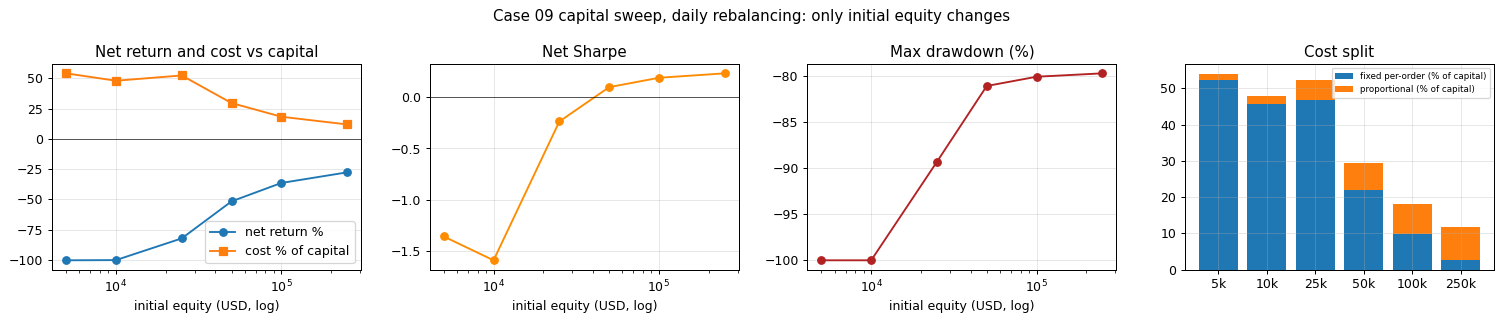

capital sweep, monthly rebalancing


capital,5000,10000,25000,50000,100000,250000
gross_usd,-571.675,-1143.349,-2858.373,-5716.745,-11433.490,-28583.725
net_usd,-1271.486,-1936.269,-3943.091,-7325.124,-14197.035,-35070.907
net_return,-25.430,-19.360,-15.770,-14.650,-14.200,-14.030
cost_share,11.070,6.480,3.780,2.960,2.640,2.530
sharpe,0.247,0.273,0.287,0.292,0.294,0.294
max_drawdown,-79.840,-79.640,-79.520,-79.480,-79.460,-79.460
fixed_cost_usd,436.394,404.891,323.185,227.074,135.294,59.099
proportional_cost_usd,117.231,243.242,621.132,1250.536,2507.932,6276.361
cost_usd,553.626,648.132,944.318,1477.610,2643.227,6335.460


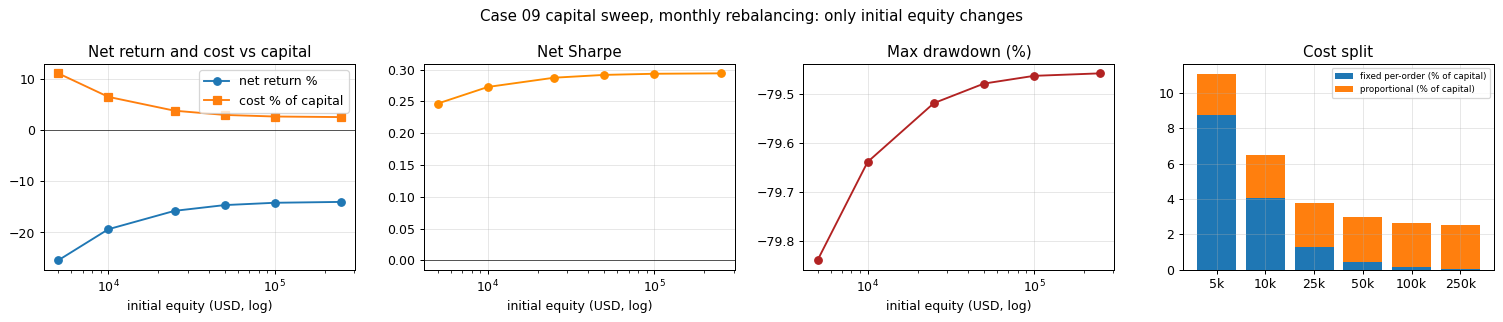

In [ ]:
def run_at_capital(cap_: float, f: str) -> Dict[str, float]:
    c = simulate(PRICES, DAY_HIGH, DAY_LOW, f, float(cap_), PARAMS)
    g = simulate(PRICES, DAY_HIGH, DAY_LOW, f, float(cap_), PARAMS, apply_costs=False)
    eq = c["equity"]
    sm = performance_summary(c["daily_return"].iloc[1:].clip(lower=-1.0), periods_per_year=ppy)
    fixed = float(c["fixed_cost"].sum())
    total = float(c["cost"].sum())
    return {"gross_usd": float(g["equity"].iloc[-1] - cap_), "net_usd": float(eq.iloc[-1] - cap_), "net_return": float(eq.iloc[-1] / cap_ - 1.0),
            "cost_share": total / cap_, "sharpe": float(sm["sharpe"]), "max_drawdown": float(sm["max_drawdown"]),
            "fixed_cost_usd": fixed, "proportional_cost_usd": total - fixed, "cost_usd": total}


_caps = [5_000, 10_000, 25_000, 50_000, 100_000, 250_000] if not SYNTHETIC else [5_000, 100_000]
for f in ("daily", "monthly"):
    sw = capital_sweep(lambda c, f=f: run_at_capital(c, f), _caps)
    show = sw.copy()
    for col in ["net_return", "cost_share", "max_drawdown"]:
        show[col] = (show[col] * 100).round(2)
    print(f"capital sweep, {f} rebalancing")
    display(show.round(3).set_index("capital").T)
    plot_capital_sweep(sw, title=f"Case 06 capital sweep, {f} rebalancing: only initial equity changes")
    plt.show()
    RESULTS[f"capital_sweep_{f}"] = sw.round(6).to_dict("records")

## 9. Interpretation

**Headline, at 100,000 USD of illustrative equity.** The equal-weight basket lost money gross over this window: daily rebalancing would have ended at 86,148 USD with no costs and monthly at 88,567 USD. With the fee model, daily rebalancing ends at 63,551 USD (-36.4%, Sharpe 0.19, maximum drawdown -80.0%) and monthly at 85,803 USD (-14.2%, Sharpe 0.29, maximum drawdown -79.5%). Daily rebalancing pays 18,220 USD of costs (18.2% of equity) against 2,643 USD (2.6%) for monthly: frequency is a pure cost lever on a portfolio with nothing to predict. (The annualised Sharpe is positive for every frequency while the total return is negative: with a volatility near 68% a year the arithmetic mean daily return is positive and volatility drag turns the compounded return negative.) The rest of the loss is the market: a basket with BCH and LTC in it was not a good basket, and holding it with no fees would also have lost.

**Does the ruin survive the sweep? The honest answer.** The case set out to test a loss that goes below zero. It does, but not where one might guess. At the illustrative tiny account of 1,000 USD, 3 of the four variants end below zero (the monthly one survives). From 5,000 USD up, equity reaches zero only for **daily** rebalancing at 10,000 USD and below (a total of 2 runs out of 24 across the sweep); weekly, two-weekly and monthly rebalancing never do (0 of those runs), and at 100,000 USD none of the four does (0 runs). At 5,000 USD daily rebalancing ends at -13 USD and the fixed minimum is 97% of its cost (against 53% at 100,000 USD); at the tiny size it ends at -1.4 USD. So the failure is **conditional on small equity and frequent trading**, a minimum-ticket effect, and not a property of the strategy at the headline size. The headline loss at 100,000 USD is a cost-model and market loss, not ruin.

**What the minimum does.** Below a notional of about 972 USD a trade pays 1.75 USD whatever its size. A daily rebalance of five assets corrects only the *drift*, which is a small slice of each position: on a 5,000 USD account the typical correction is a few dozen USD, so it pays the minimum and the fee in basis points is in the hundreds. Costs then scale as the number of orders, not as the notional, and compounding turns a daily fee that is a few basis points of equity into a drain that outruns the market return. This is why cost share of equity rises faster than 1 over equity in the capital sweep.

**The ruin floor.** The model lets equity go negative and keeps trading with a fee floor that applies to a negative balance, which has no meaning. Section 7.1 shows the runs that cross zero and the same runs stopped at the first breach: the no-floor model reports a final equity below zero (a return worse than -100%), which no account can have, and the stopped version shows how much of the sample the account would have survived.

**Honest label.** Cost model is the primary tag: it explains why frequency and size change the result, and it is what a reader can act on. No ruin floor is the secondary tag and is **conditional**: it applies to the small-account rows of the sweep (and to most frequencies at the tiny account), not to the headline.

## 10. The lesson

**Put the fee floor and a ruin floor in the model before you read the P&L, and run the capital sweep before you claim a ruin.** A proportional cost model and an equity path that cannot go below zero describe a different, friendlier account than the one a minimum ticket describes. The sweep showed that the dramatic result (an account below zero) is a small-account, high-frequency result; stating it at the headline size would have been wrong.

## 11. What I would do differently

* **Run the ruin sweep first, then choose the headline.** The check is five lines and decides what can honestly be said.
* **Model the fixed part of fees separately** and print the break-even ticket next to the first result.
* **Rebalance on a threshold, not on a clock.** A drift band of a few percentage points removes most of the tiny orders that pay the minimum.
* **Stop the simulation at the margin call** and report the stopped path.

## 12. How to improve it (ideas, not claims)

* Rebalance only when an asset's weight is more than a band away from target.
* Compare with a market-cap-weighted basket and with BTC alone (a benchmark this case does not define).
* Use measured fills (maker or taker fees from the venue) in place of the range-based slippage assumption.
* Test a minimum account size below which the strategy is simply not run.

## 13. FAQ

**Is the strategy's idea wrong?** There is no idea beyond holding five assets equally. The window was a poor one for this basket gross of fees.

**Is 1.75 USD per order really the broker's minimum?** It is the figure from the broker's published crypto schedule; it was not re-verified against the current page for this publication. The conclusion is about the existence of a floor, not its exact level.

**Why 365 days?** Crypto trades every calendar day; annualising on 252 would understate volatility.

**Why a 1,000 USD row?** It is an extra illustrative tiny account that shows the extreme of the minimum-ticket effect.

**Does the failure reproduce in synthetic mode?** No. Synthetic prices are driftless random walks; the code runs end to end and the sweep shows the same minimum-ticket mechanism, but not the published numbers.

## 14. References

* Interactive Brokers. Cryptocurrency commissions (published fee schedule); not re-verified for this publication.
* Perold, A. F. and Sharpe, W. F. (1988). Dynamic strategies for asset allocation. *Financial Analysts Journal*, 44, 16-27 (rebalancing).
* Magdon-Ismail, M. and Atiya, A. F. (2004). Maximum drawdown. *Risk*, 17 (drawdown and ruin).
* Bailey, D. H. and Lopez de Prado, M. (2014). The deflated Sharpe ratio. *Journal of Portfolio Management*.

## 15. Disclaimer

This notebook is educational. It documents a failed research experiment and is not financial advice or a recommendation to trade any instrument. Crypto assets are highly volatile and can lose all of their value. Past or hypothetical results do not predict future results. The code is provided as is, without warranty.

In [ ]:
if os.environ.get("AUTOPSY_RESULTS_JSON"):
    Path(os.environ["AUTOPSY_RESULTS_JSON"]).write_text(json.dumps(RESULTS, indent=2, default=str))
print("done")

done
